# Genetic Algorithm (GA) for quadrotor controller tuning

**Author: Mohammad ALbaraj**

[Notebook index](README.md) · [Main project](../README.md)

Run cells from top to bottom. Saved results and fresh examples are labeled separately. Scientific source modules remain the authoritative implementation.


In [1]:
from pathlib import Path
import sys, json, csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Code

# Works when launched from the repository root or any notebook subdirectory.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'CITATION.cff').exists() and (p / 'all work').is_dir())
if str(ROOT / 'notebooks') not in sys.path:
    sys.path.insert(0, str(ROOT / 'notebooks'))
from notebook_support import (METHODS, ORIGINAL, NOMINAL, ROBUST, study, load_json,
    load_csv, show_table, show_source, source_index, load_runs, fitness_summary,
    convergence_plot, validation_rows, validation_summary, figures, file_links,
    show_figures, gallery, isolated_python, demo_source)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 10})
print('Project loaded. Default cells do not launch full optimization campaigns.')


Project loaded. Default cells do not launch full optimization campaigns.


## Algorithm walkthrough

The real-coded GA evolves a population of candidate gain vectors. Each coordinate is a normalized logarithmic gain.

1. Create 64 stratified random candidates and insert the original controller.
2. Evaluate the constrained objective, sort the population, and retain four elites.
3. Select parents using tournaments of three candidates.
4. With probability 0.9, blend parents using coordinate-wise weights drawn from [-0.15, 1.15].
5. Mutate each coordinate with probability 0.25 using Gaussian noise. Clip trial coordinates to [0, 1]. Random immigrants are proposed with probability 0.08.
6. Repeat for 50 generations; mutation sigma decreases from 0.14 to 0.035. Return the best retained candidate.

Elitism preserves good solutions while mutation and immigrants explore alternatives. In the separate strict-budget benchmark, the mutation schedule follows evaluation-budget progress rather than generation number.

Read [study.py](../all%20work/pid%20using%20ga/study.py) for the implemented update rules, [config.json](../all%20work/pid%20using%20ga/config.json) for settings, and [study.py](../all%20work/pid%20using%20ga/study.py) for objective evaluation.


In [2]:
METHOD='GA'
FOLDER=study(METHOD)
cfg=load_json(FOLDER/'config.json')
show_table([{'setting':k,'value':v} for k,v in cfg.items() if k!='parameters'],limit=60)


setting,value
study_name,Equation-based GA attitude tuning of AttitudeControl_Sim
integration_dt_s,0.001
controller_dt_s,0.001
mixer_dt_s,0.004
pre_step_s,0.2
response_horizon_s,3.0
settling_band_fraction,0.02
minimum_final_hold_s,0.25
max_overshoot_fraction,0.1
max_final_error_fraction,0.02


## Exact implementation
This displays the authoritative Python source rather than a separately reimplemented optimizer. The six extensions share one module containing their distinct update rules.


In [3]:
show_source(FOLDER/METHODS[METHOD][2], 'genetic_algorithm')


def genetic_algorithm(cfg,scenarios,seed,outdir,initial=None,label='main'):
    outdir=Path(outdir); outdir.mkdir(parents=True,exist_ok=True)
    rng=np.random.default_rng(seed); size=cfg['population']; dims=len(cfg['parameters'])
    population=rng.random((size,dims))
    # Stratified initialization reduces empty portions of each parameter interval.
    for j in range(dims): population[:,j]=(rng.permutation(size)+rng.random(size))/size
    population[0]=encode(baseline(cfg['controller_dt_s']),cfg)
    if initial is not None: population[1]=encode(np.asarray(initial),cfg)
    cache={}; history=[]; allrows=[]; start=time.perf_counter()
    def score(u):
        key=tuple(np.round(u,13))
        if key not in cache: cache[key]=evaluate(decode(u,cfg),scenarios,cfg)
        return cache[key]
    # Compile before worker threads enter Numba for the first time.
    score(population[0])
    with ThreadPoolExecutor(max_workers=cfg['workers']) as pool:
        for generation in range(cfg['generations']+1):
            values=np.array(list(pool.map(score,population)))
            order=np.argsort(values,kind='stable'); population=population[order]; values=values[order]
            physical=decode(population,cfg)
            row={'generation':generation,'best':float(values[0]),'median':float(np.median(values)),
                 'worst':float(values[-1]),'feasible_fraction':float(np.mean(values<1000)),
                 'elapsed_s':time.perf_counter()-start,'unique_evaluations':len(cache)}
            history.append(row)
            for rank in range(size):
                allrows.append({'generation':generation,'rank':rank,'fitness':values[rank],
                                **dict(zip([p['name'] for p in cfg['parameters']],physical[rank]))})
            if generation%5==0 or generation==cfg['generations']:
                print(f'{label} seed={seed} generation={generation:02d} fitness={values[0]:.6g} feasible={row["feasible_fraction"]:.0%}',flush=True)
                (outdir/f'checkpoint_{label}_{seed}.json').write_text(json.dumps({'seed':seed,'history':history,'gains':physical[0].tolist()},indent=2))
            if generation==cfg['generations']: break
            new=[p.copy() for p in population[:cfg['elitism']]]
            sigma=cfg['mutation_sigma_start']+(cfg['mutation_sigma_end']-cfg['mutation_sigma_start'])*generation/max(1,cfg['generations'])
            def parent():
                indices=rng.integers(size,size=cfg['tournament_size'])
                return population[indices[np.argmin(values[indices])]]
            while len(new)<size:
                if rng.random()<cfg['random_immigrant_fraction']:
                    new.append(rng.random(dims)); continue
                a=parent(); b=parent(); child=a.copy()
                if rng.random()<cfg['crossover_probability']:
                    blend=rng.uniform(-.15,1.15,dims); child=blend*a+(1-blend)*b
                mutate=rng.random(dims)<cfg['mutation_probability_per_gene']
                child+=mutate*rng.normal(0,sigma,dims)
                new.append(np.clip(child,0,1))
            population=np.asarray(new)
    write_csv(outdir/f'history_{label}_{seed}.csv',history)
    write_csv(outdir/f'population_{label}_{seed}.csv',allrows)
    result={'seed':seed,'fitness':float(values[0]),'gains':physical[0].tolist(),
            'seconds':time.perf_counter()-start,'unique_evaluations':len(cache),'history':history}
    (outdir/f'run_{label}_{seed}.json').write_text(json.dumps(result,indent=2))
    return result

## Original three-seed study
These iteration-based results are separate from the strict-budget benchmark below. Unique evaluation counts differ across methods.


In [4]:
original_runs=[load_json(FOLDER/f'results/run_main_{seed}.json') for seed in [11,29,47]]
show_table(original_runs,['seed','fitness','unique_evaluations','seconds'])
show_table([{'gain':k,'value':v} for k,v in load_json(FOLDER/'results/best_gains.json')['gains'].items()])


seed,fitness,unique_evaluations,seconds
11,0.05278799266948063,3030,8.267284800007474
29,0.052633873024386914,3035,7.638262399996165
47,0.05226508591371648,3024,10.284501199988881


gain,value
roll_outer_K,16.12697047753728
roll_inner_Kp_equivalent,0.15005147486803522
roll_inner_Ki_equivalent,0.006571115221422931
pitch_outer_K,11.309904024933516
pitch_inner_Kp_equivalent,0.06902441961463411
pitch_inner_Ki_equivalent,0.0033348250066867454
yaw_Kp,0.3853537558017292
yaw_Ki,0.08212975831659704


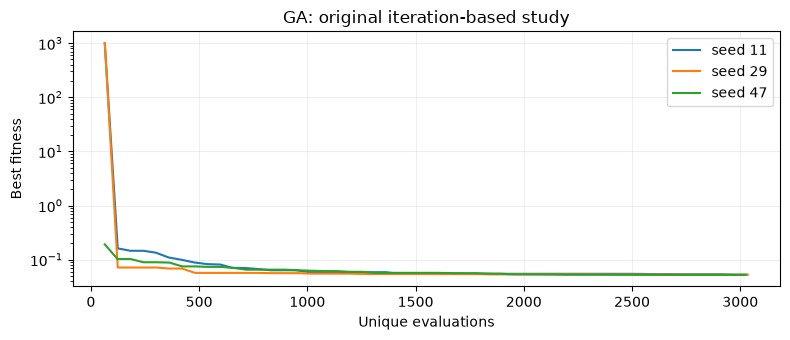

In [5]:
fig,ax=plt.subplots(figsize=(8,3.5))
for record in original_runs:
    history=record['history']
    ax.plot([h['unique_evaluations'] for h in history],[h['best'] for h in history],label=f"seed {record['seed']}")
ax.set(xlabel='Unique evaluations',ylabel='Best fitness',yscale='log',title=f'{METHOD}: original iteration-based study')
ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); plt.show(); plt.close(fig)


## Paired 30-seed results
These summaries are recomputed from saved run records. Nominal and robust fitness use different training sets. Means retain infeasible penalties; medians alone can hide a failed run.


method,regime,runs,best,median,mean,sample_sd,feasible
GA,nominal,30,0.0513596826213876,0.05226312547838116,0.05234592317298383,0.00047155332220080037,30
GA,robust,30,0.06573136108055574,0.06699187362751968,0.0670648903446438,0.0009680660401343237,30


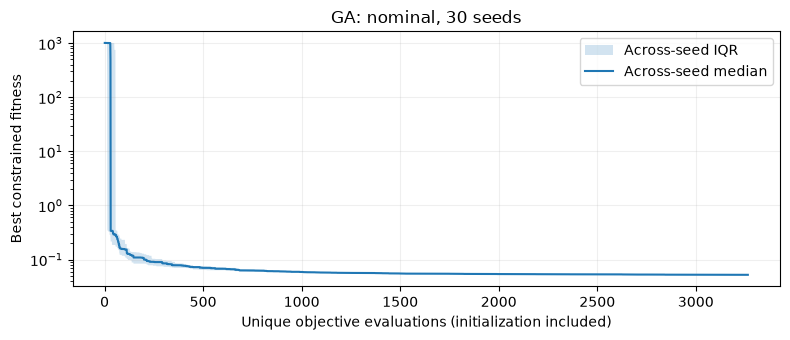

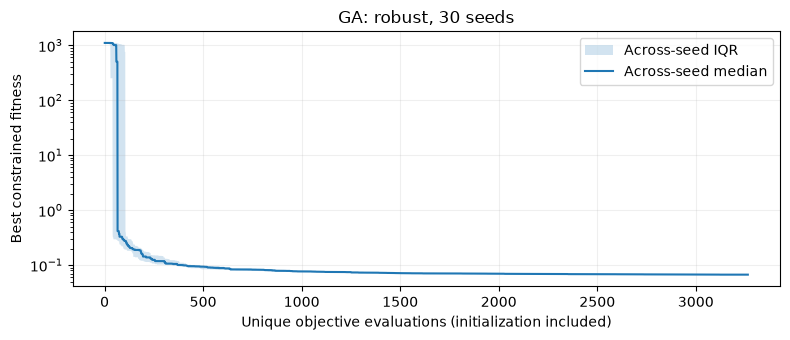

In [6]:
show_table(fitness_summary([METHOD]))
convergence_plot(METHOD,"nominal")
convergence_plot(METHOD,"robust")


## Held-out validation
Each later validation suite contains 300 random single-axis, 54 one-factor boundary, and 90 combined-axis cases. The table gives the range across seeds, not an independent probability of hardware success.


In [7]:
show_table(validation_summary(METHOD))


method,training,suite,cases_per_controller,minimum_passes,median_passes,maximum_passes
GA,nominal,Random single-axis,300,297,298.0,299
GA,nominal,One-factor boundaries,54,49,51.0,53
GA,nominal,Combined-axis stress,90,0,0.0,0
GA,robust,Random single-axis,300,300,300.0,300
GA,robust,One-factor boundaries,54,53,53.0,54
GA,robust,Combined-axis stress,90,0,0.0,0


## Saved figures
The first three images are previews; the full index below links every saved PNG for this method. The complete gallery notebook covers all methods.


**all work/pid using ga/results/plots/01_step_responses.png**

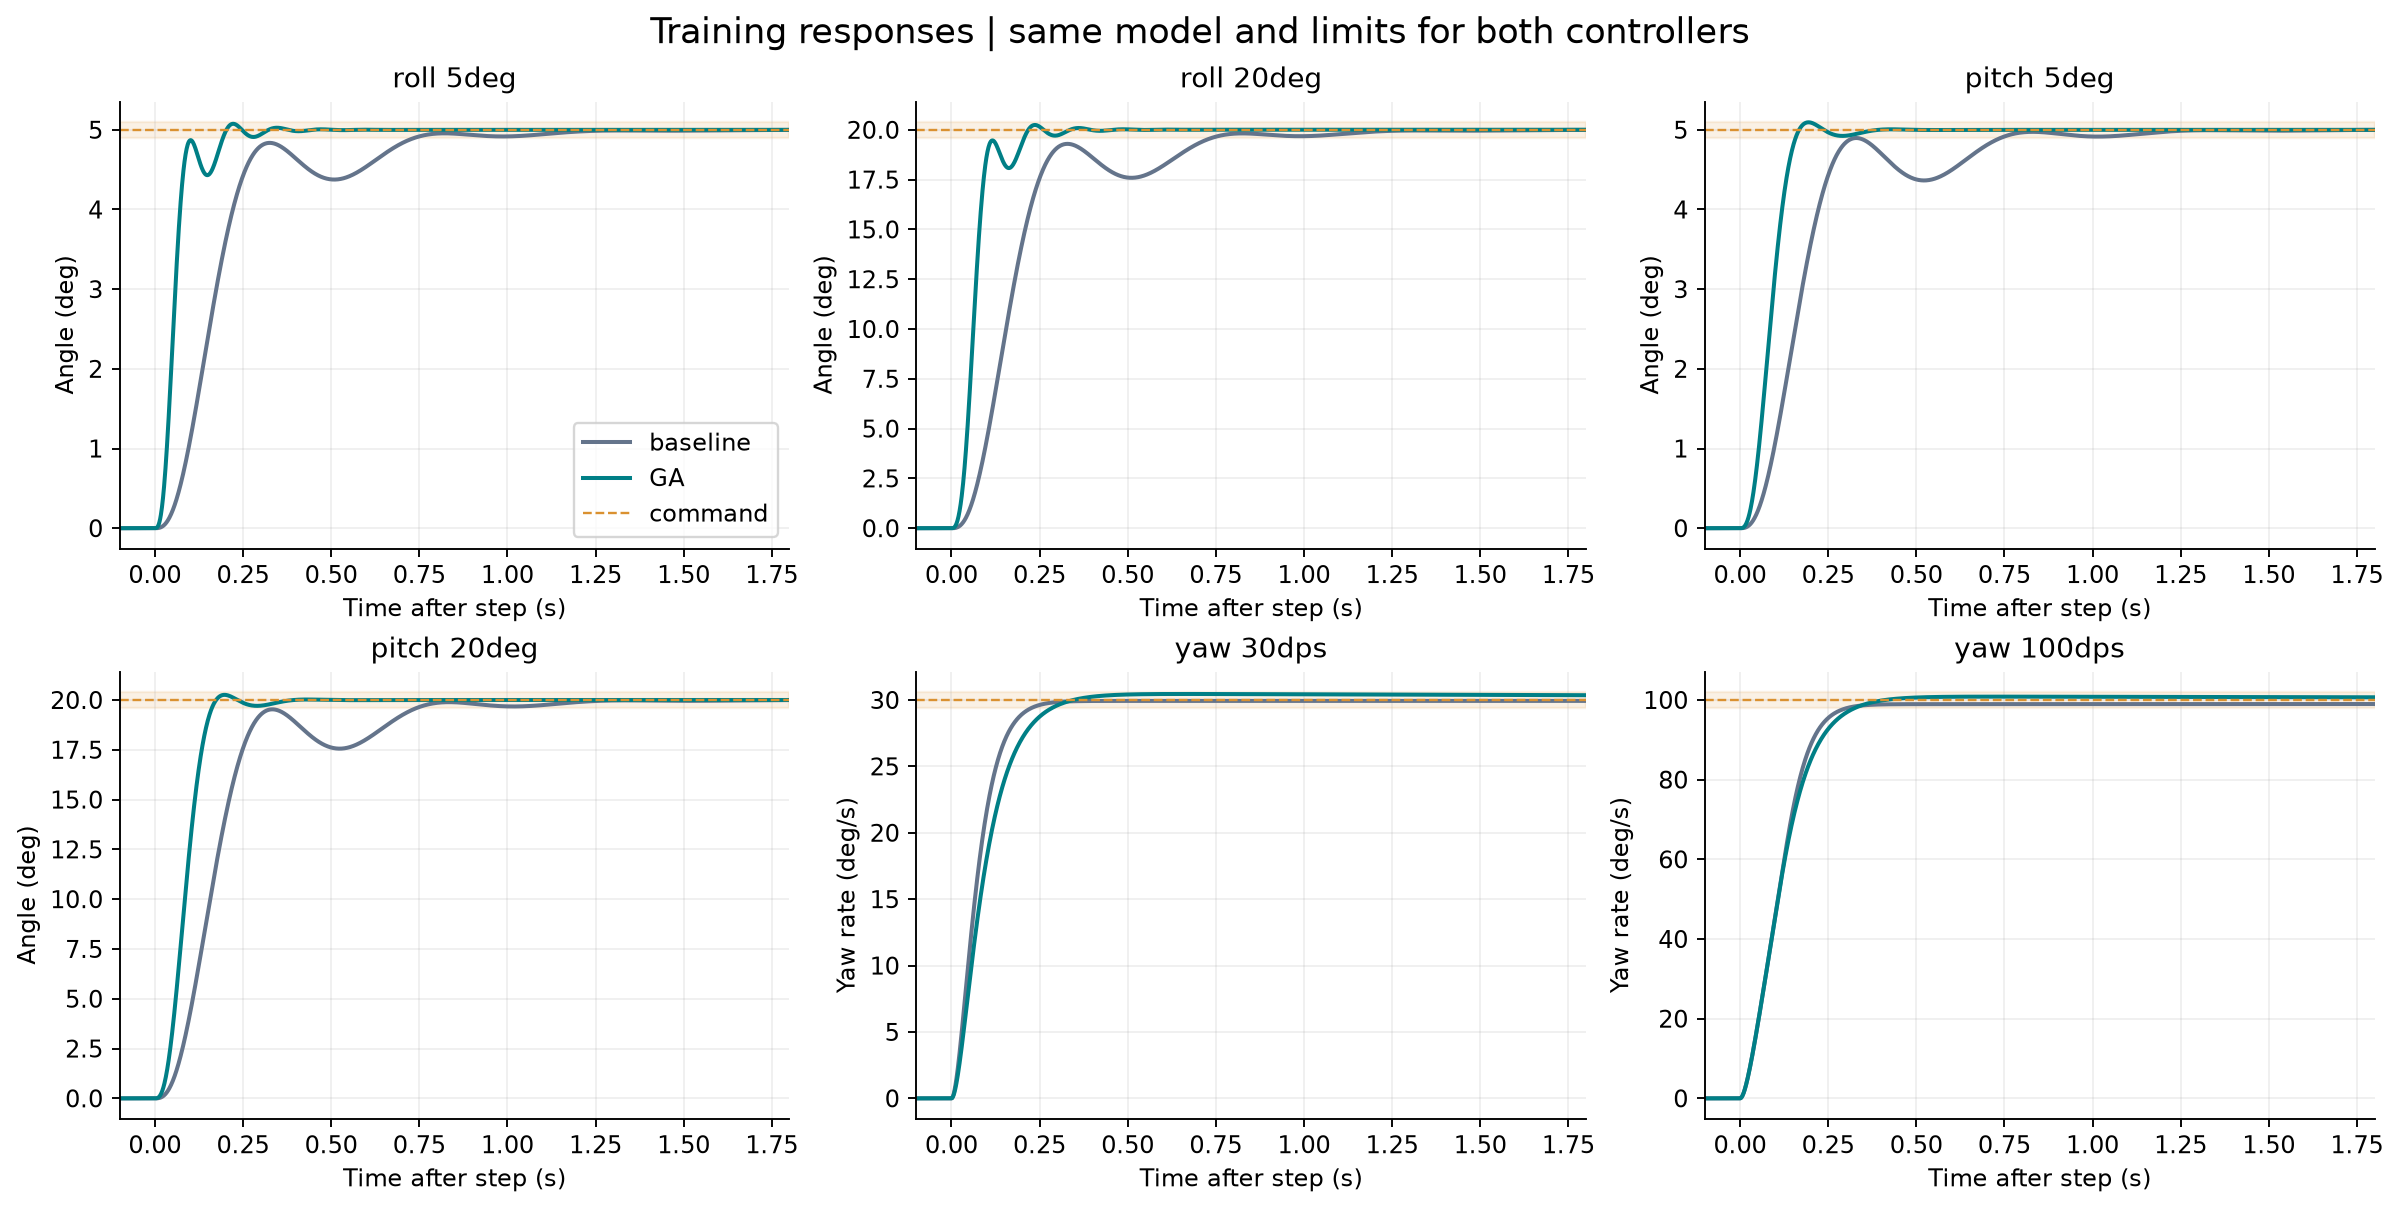

**all work/pid using ga/results/plots/02_ga_iterations.png**

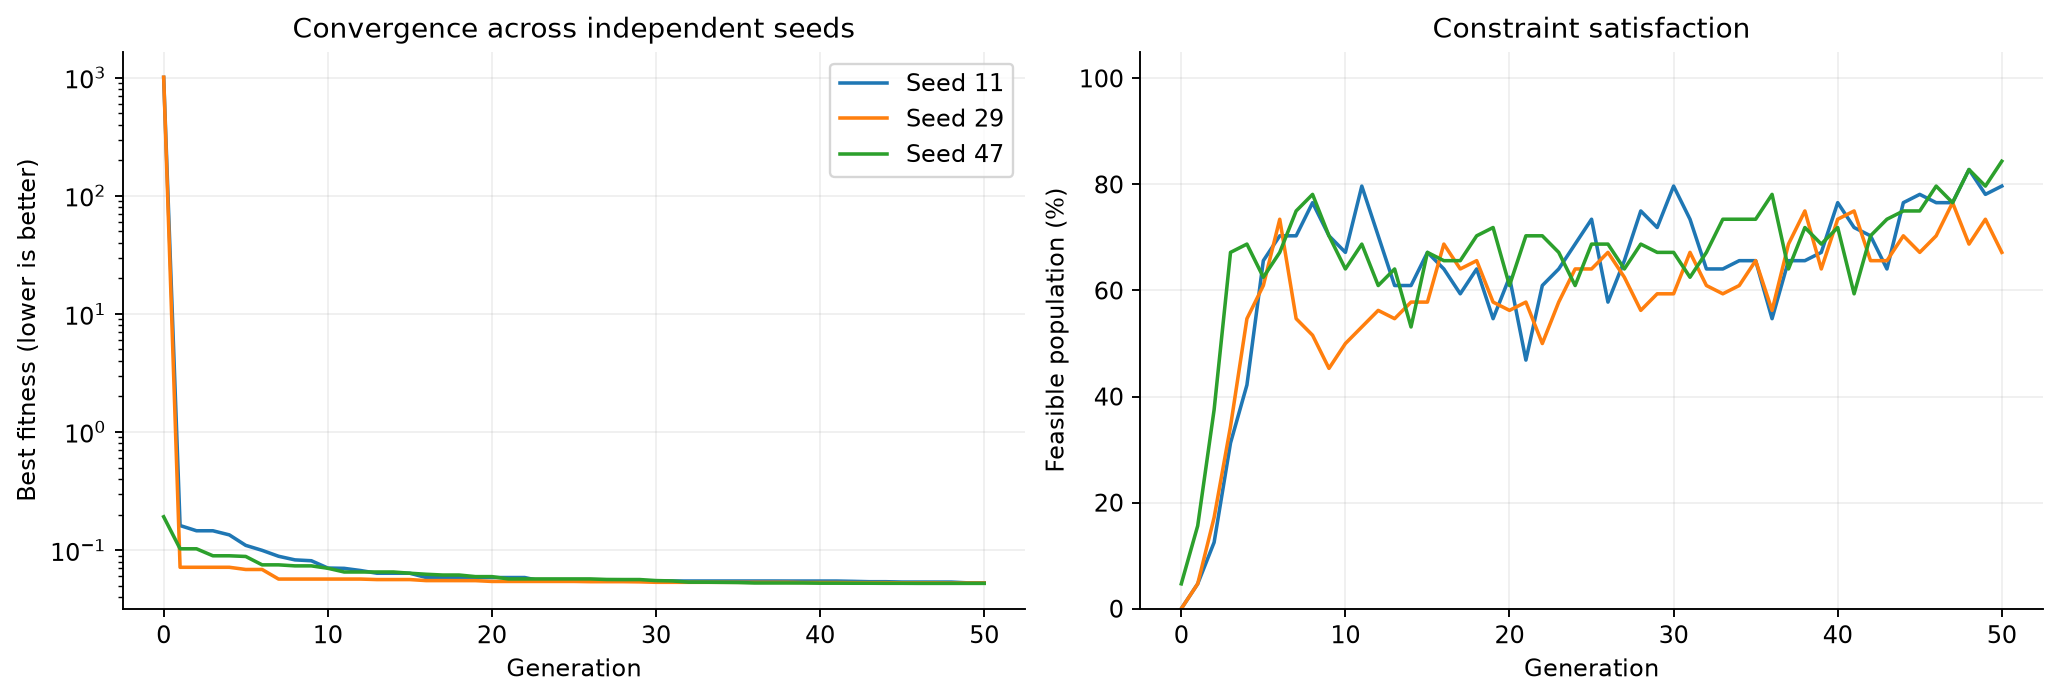

**all work/pid using ga/results/plots/03_coupled_and_saturation.png**

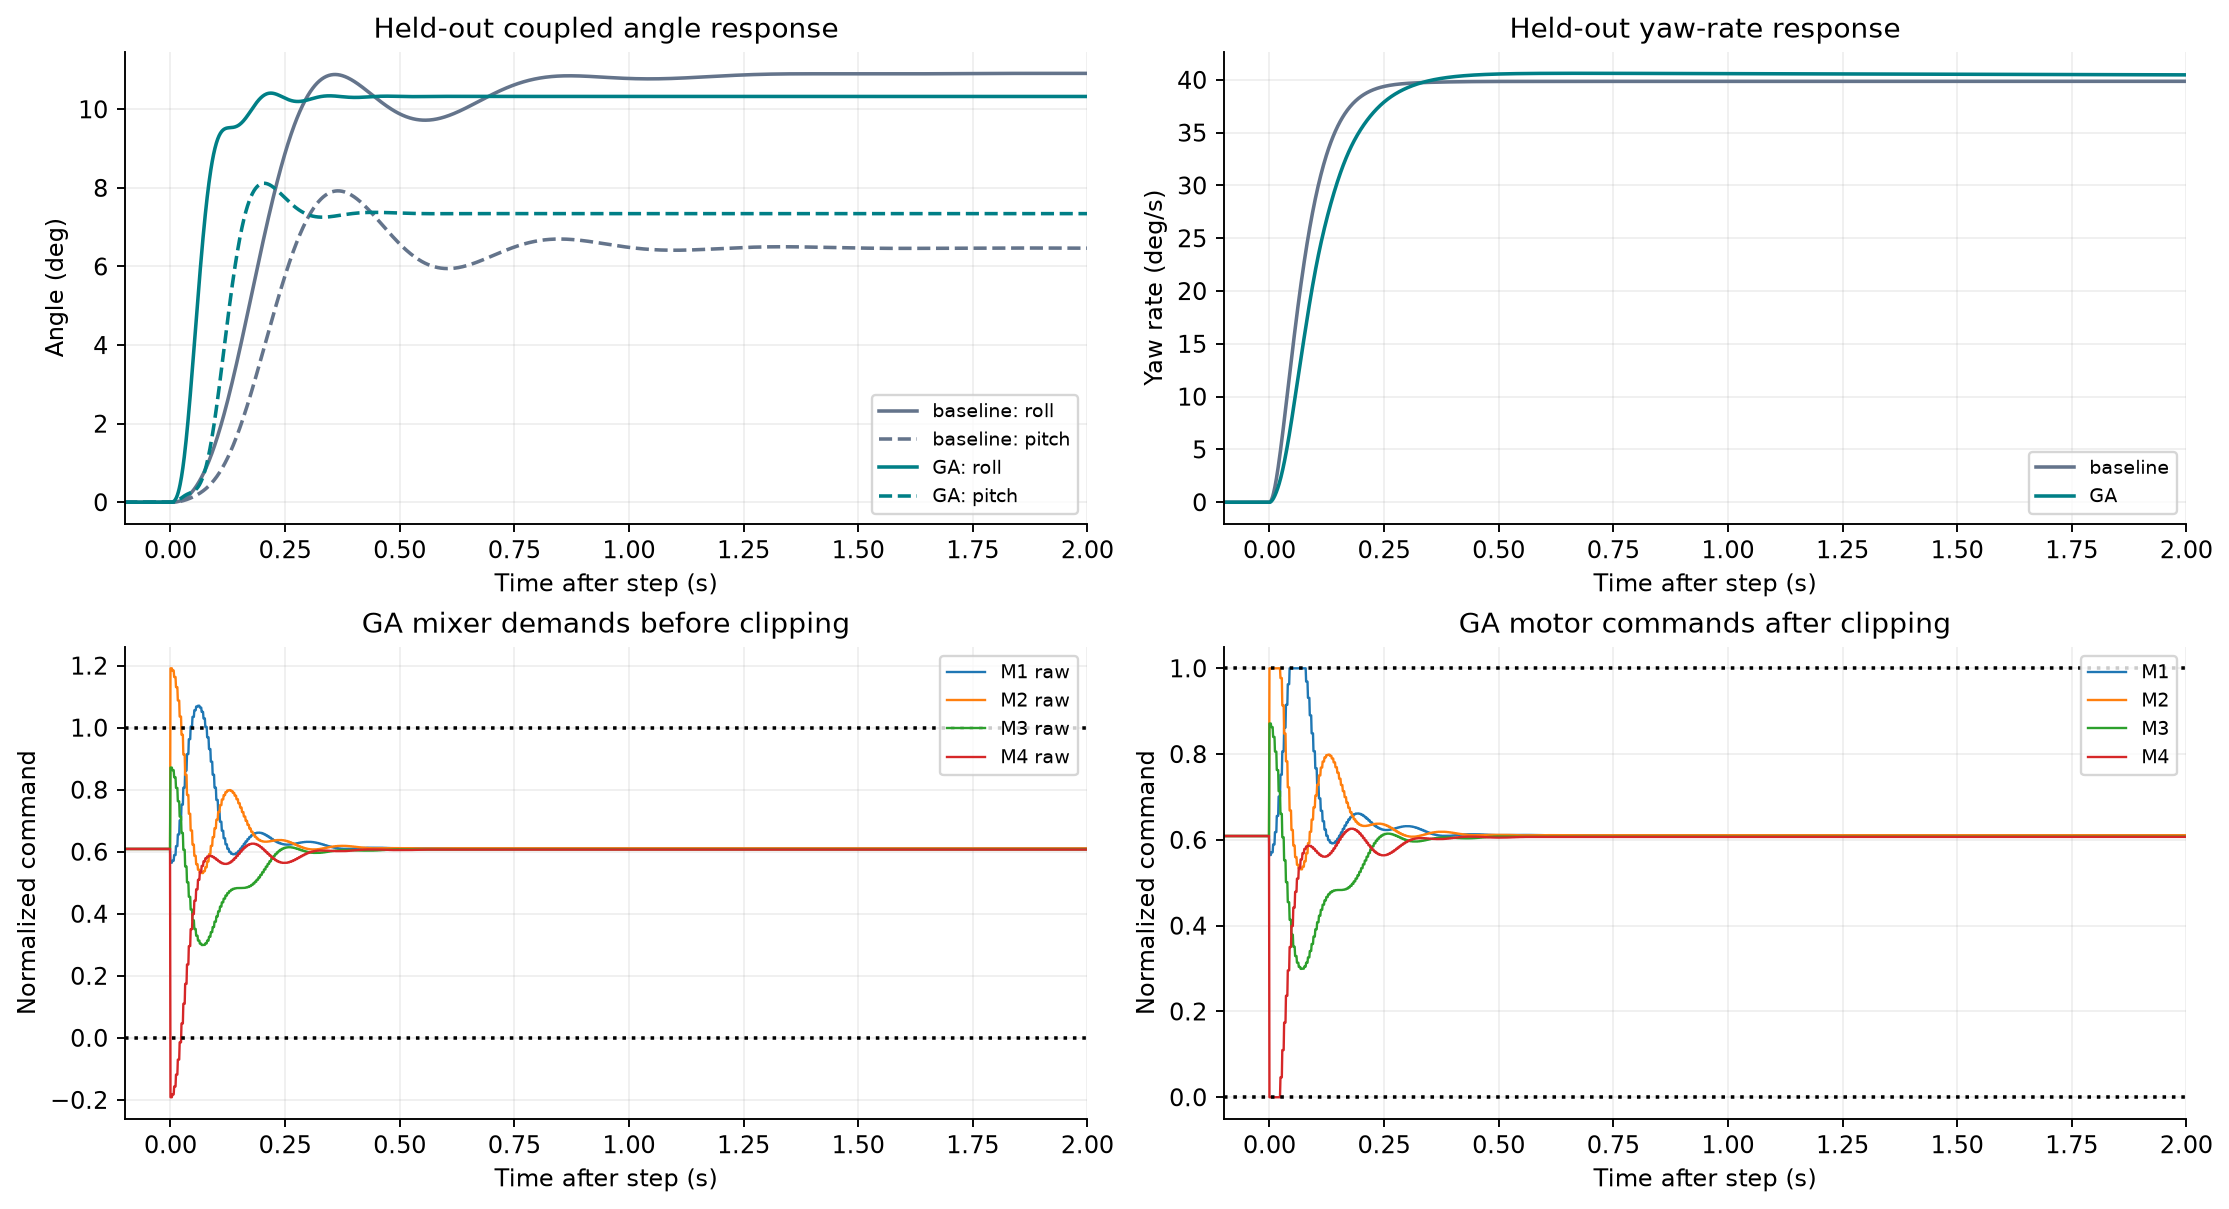

### All saved method figures
- [all work/pid using ga/results/plots/01_step_responses.png](../all%20work/pid%20using%20ga/results/plots/01_step_responses.png)
- [all work/pid using ga/results/plots/02_ga_iterations.png](../all%20work/pid%20using%20ga/results/plots/02_ga_iterations.png)
- [all work/pid using ga/results/plots/03_coupled_and_saturation.png](../all%20work/pid%20using%20ga/results/plots/03_coupled_and_saturation.png)
- [all work/pid using ga/results/plots/04_inner_loops.png](../all%20work/pid%20using%20ga/results/plots/04_inner_loops.png)
- [all work/pid using ga/results/plots/05_robustness.png](../all%20work/pid%20using%20ga/results/plots/05_robustness.png)
- [all work/pid using ga/results/plots/06_gain_sensitivity.png](../all%20work/pid%20using%20ga/results/plots/06_gain_sensitivity.png)
- [all work/pid using ga/results/plots/07_metric_comparison.png](../all%20work/pid%20using%20ga/results/plots/07_metric_comparison.png)
- [all work/pid using ga/results/plots/08_fitness_components.png](../all%20work/pid%20using%20ga/results/plots/08_fitness_components.png)
- [all work/pid using ga/results/plots/09_robust_candidate.png](../all%20work/pid%20using%20ga/results/plots/09_robust_candidate.png)

In [8]:
method_figures=figures(METHOD)
show_figures(method_figures,limit=3)
file_links(method_figures,"All saved method figures")


## Try a small fresh optimization (opt-in)
The displayed code uses the original implementation. It runs a small nominal search in `notebook_outputs/`, not the full published experiment. Set the switch to True to execute; new results are not comparable to the full-budget archive.


In [9]:
small_search_code=demo_source(METHOD)
display(Code(small_search_code,language="python"))
RUN_SMALL_SEARCH=False
if RUN_SMALL_SEARCH:
    isolated_python(METHOD,small_search_code,timeout=600)
else:
    print("Small search disabled. Set RUN_SMALL_SEARCH=True to execute.")


from pathlib import Path
import json, os
cfg=json.loads(Path('config.json').read_text())
out=Path(os.environ['PID_NOTEBOOK_OUTPUT'])/'small_search'
out.mkdir(exist_ok=True)
from study import training_scenarios
from study import genetic_algorithm
cfg.update(population=8,swarm_size=8,generations=2,iterations=2,workers=1)
result=genetic_algorithm(cfg,training_scenarios(),2026,out)
print('Fresh small-search fitness:',result['fitness'])

Small search disabled. Set RUN_SMALL_SEARCH=True to execute.


## Full experiment and limitations
Use the linked study README for full commands, exact output files, and interpretation. Never run a modified protocol into the archived `results/`. The notebooks do not certify continuous-range robustness, global optimality, Simulink equivalence, or hardware readiness.

[Detailed study guide](../all%20work/pid%20using%20ga/README.md) · [Data checks](../docs/DATA.md)
